# Clash Royale — Multiple Correspondence Analysis
ISYE 6416 Final Project

Analyze the 1,000 high-trophy winning match records using full binary MCA from scratch. Run cells in order. Upload the two cleaned CSV files when prompted. No Kaggle download or GPU is needed.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

N_COMPONENTS = 20
OUT = Path("mca_results")
OUT.mkdir(exist_ok=True)

## 1. Upload cleaned data
Upload `1000_best_players.csv` and `CardMasterListSeason18.csv`. If they already exist in the current directory, this cell skips the upload.

In [3]:
import pandas as pd
from pathlib import Path

required = [
    "/content/1000_best_players.csv",
    "/content/CardMasterListSeason18.csv"
]

assert all(Path(f).exists() for f in required), \
    "Upload both CSV files using the Files sidebar."

matches = pd.read_csv(required[0])
catalog = pd.read_csv(required[1])

print("Matches:", len(matches))
print("Cards:", len(catalog))

display(matches.head(3))
display(catalog.head(3))

Matches: 1000
Cards: 102


,Unnamed: 0,battleTime,arena.id,gameMode.id,average.startingTrophies,winner.tag,winner.startingTrophies,winner.trophyChange,winner.crowns,winner.kingTowerHitPoints,...,loser.cards.list,loser.totalcard.level,loser.troop.count,loser.structure.count,loser.spell.count,loser.common.count,loser.rare.count,loser.epic.count,loser.legendary.count,loser.elixir.average
0,8648462,2020-12-07 07:38:57+00:00,54000031.0,72000201.0,8193.5,#290QP2C,8212.0,26.0,1.0,5832.0,...,"[26000035, 26000037, 26000046, 26000051, 26000...",104,6,0,2,0,2,1,5,3.375
1,8648506,2020-12-07 07:40:03+00:00,54000031.0,72000201.0,8209.0,#YP9VPGUUG,8210.0,29.0,1.0,5832.0,...,"[26000015, 26000023, 26000027, 26000085, 27000...",104,4,1,3,0,1,6,1,4.250
2,8649460,2020-12-07 08:03:43+00:00,54000031.0,72000201.0,8220.0,#9RGQ8YC,8207.0,32.0,1.0,4438.0,...,"[26000035, 26000037, 26000046, 26000051, 26000...",104,6,0,2,0,2,1,5,3.375


,team.card1.id,team.card1.name
0,26000000,Knight
1,26000001,Archers
2,26000002,Goblins


## 2. Encode winning decks
Each row has eight ones; all other entries are zero. Repeated players and repeated decks are retained.

In [4]:
ids = catalog["team.card1.id"].to_numpy()
names = catalog["team.card1.name"].to_numpy()
columns = [f"winner.card{i}.id" for i in range(1, 9)]
decks = matches[columns].to_numpy()
lookup = {card: j for j, card in enumerate(ids)}
X = np.zeros((len(decks), len(ids)), dtype=np.uint8)
for i, deck in enumerate(decks):
    if len(set(deck)) != 8 or not all(card in lookup for card in deck):
        raise ValueError(f"Invalid deck at row {i}")
    X[i, [lookup[card] for card in deck]] = 1
assert np.all(X.sum(axis=1) == 8)
print("Binary matrix:", X.shape)
display(pd.DataFrame(X, columns=names).head())

Binary matrix: (1000, 102)


,Knight,Archers,Goblins,Giant,P.E.K.K.A,Minions,Balloon,Witch,Barbarians,Golem,...,Poison,Graveyard,The Log,Tornado,Clone,Earthquake,Barbarian Barrel,Heal Spirit,Giant Snowball,Royal Delivery
0,1,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,1,0,0,1,0
1,0,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,1,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,1,1,0,0
4,0,0,0,0,1,0,1,0,0,0,...,0,0,0,1,0,0,0,0,0,0


## 3. Full binary MCA from scratch
Remove constant variables, then construct the complete indicator matrix $Z=[A,1-A]$. Normalize it and apply SVD to the standardized residual matrix. The eigenvalues are squared singular values; their normalized values are explained inertia.

In [5]:
p = X.mean(axis=0)
active = (p > 0) & (p < 1)
A = X[:, active].astype(float)
n, m = A.shape
Z = np.concatenate([A, 1-A], axis=1)
P = Z / Z.sum()
r, c = P.sum(axis=1), P.sum(axis=0)
S = (P - np.outer(r, c)) / np.sqrt(np.outer(r, c))
U, s, Vt = np.linalg.svd(S, full_matrices=False)
eigenvalues = s**2
rank = int(np.sum(s > 1e-12))
d = min(N_COMPONENTS, rank)
inertia = eigenvalues / eigenvalues.sum()
F = U[:, :d] * s[:d] / np.sqrt(r[:, None])
G = Vt[:d].T * s[:d] / np.sqrt(c[:, None])
contributions = c[:, None] * G**2 / eigenvalues[:d]
assert np.allclose(contributions.sum(axis=0), 1)
print("Active cards:", m, "| Rank:", rank, "| Reduced matrix:", F.shape)
print("Excluded cards:", ", ".join(names[~active]))
print(f"Retained inertia: {inertia[:d].sum()*100:.2f}%")

Active cards: 97 | Rank: 96 | Reduced matrix: (1000, 20)
Excluded cards: Witch, Mother Witch, Cannon, Goblin Hut, Furnace
Retained inertia: 68.27%


## 4. Scree plot and cumulative inertia
Use these to assess dimensionality. Twenty dimensions is an initial choice, not a validated optimum.

,dimension,eigenvalue,inertia_percent,cumulative_percent
0,1,0.064140,6.414017,6.414017
1,2,0.060403,6.040334,12.454351
2,3,0.050141,5.014145,17.468496
3,4,0.049389,4.938851,22.407348
4,5,0.046294,4.629441,27.036789
5,6,0.043231,4.323082,31.359871
6,7,0.040263,4.026332,35.386203
7,8,0.037584,3.758375,39.144578
8,9,0.034900,3.489967,42.634544
9,10,0.033867,3.386738,46.021283


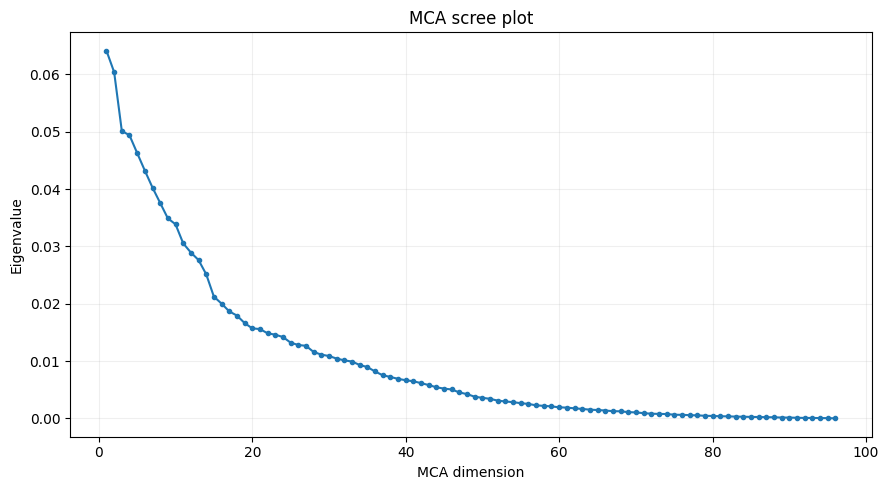

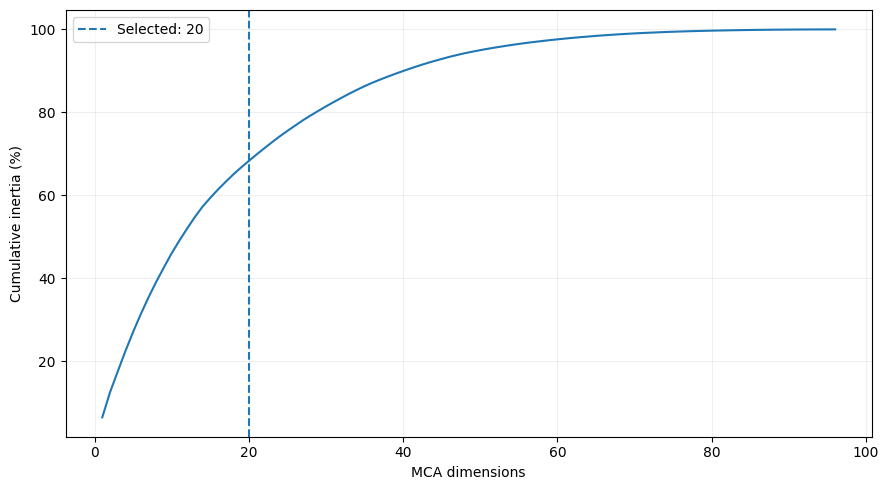

In [6]:
spectrum = pd.DataFrame({"dimension": np.arange(1, rank+1), "eigenvalue": eigenvalues[:rank], "inertia_percent": inertia[:rank]*100, "cumulative_percent": np.cumsum(inertia[:rank])*100})
display(spectrum.head(20))
plt.figure(figsize=(9,5))
plt.plot(spectrum.dimension, spectrum.eigenvalue, "o-", markersize=3)
plt.xlabel("MCA dimension"); plt.ylabel("Eigenvalue"); plt.title("MCA scree plot")
plt.grid(alpha=.2); plt.tight_layout(); plt.savefig(OUT/"scree.png", dpi=160); plt.show()
plt.figure(figsize=(9,5))
plt.plot(spectrum.dimension, spectrum.cumulative_percent)
plt.axvline(d, linestyle="--", label=f"Selected: {d}")
plt.xlabel("MCA dimensions"); plt.ylabel("Cumulative inertia (%)"); plt.legend()
plt.grid(alpha=.2); plt.tight_layout(); plt.savefig(OUT/"cumulative_inertia.png", dpi=160); plt.show()

## 5. Card relationships and contributions
Coordinates show directions of association; contributions measure how much each category defines a dimension. Signs may flip across SVD implementations without changing the analysis. The two-dimensional map captures only the inertia shown on its axes.

MCA_1 — highest contributing present categories


,card,MCA_1,contribution_percent
89,The Log,1.187670,5.327921
81,Rocket,1.784083,4.195100
0,Knight,0.993780,4.190662
71,Bomb Tower,1.323862,3.521222
93,Barbarian Barrel,-0.755596,3.514605
29,Ice Spirit,1.774401,3.188176
94,Heal Spirit,-1.072497,3.069013
57,Wall Breakers,1.305521,3.013410
82,Goblin Barrel,2.105164,2.635554
25,Princess,2.163333,2.407103


MCA_2 — highest contributing present categories


,card,MCA_2,contribution_percent
43,Hunter,-1.133844,6.692271
51,Zappies,-1.603195,5.439535
60,Fisherman,-1.336179,5.302078
92,Earthquake,-1.326481,5.045203
23,Royal Giant,-1.353084,4.874630
19,Giant Skeleton,-1.632311,4.638453
86,Zap,0.968192,3.007794
67,Electro Spirit,-1.601314,2.669623
14,Baby Dragon,0.944132,2.571106
36,Inferno Dragon,0.968197,2.495854


MCA_3 — highest contributing present categories


,card,MCA_3,contribution_percent
90,Tornado,1.165850,5.197925
81,Rocket,1.702787,4.888388
48,Bats,-1.123537,4.749599
3,Giant,-1.701206,3.808247
13,Musketeer,-1.595950,3.613423
29,Ice Spirit,1.658955,3.564849
22,Ice Wizard,1.138471,3.464323
17,Mini P.E.K.K.A,-1.829270,3.302389
11,Skeleton Army,-1.249590,2.696782
18,Spear Goblins,-0.802532,2.423298


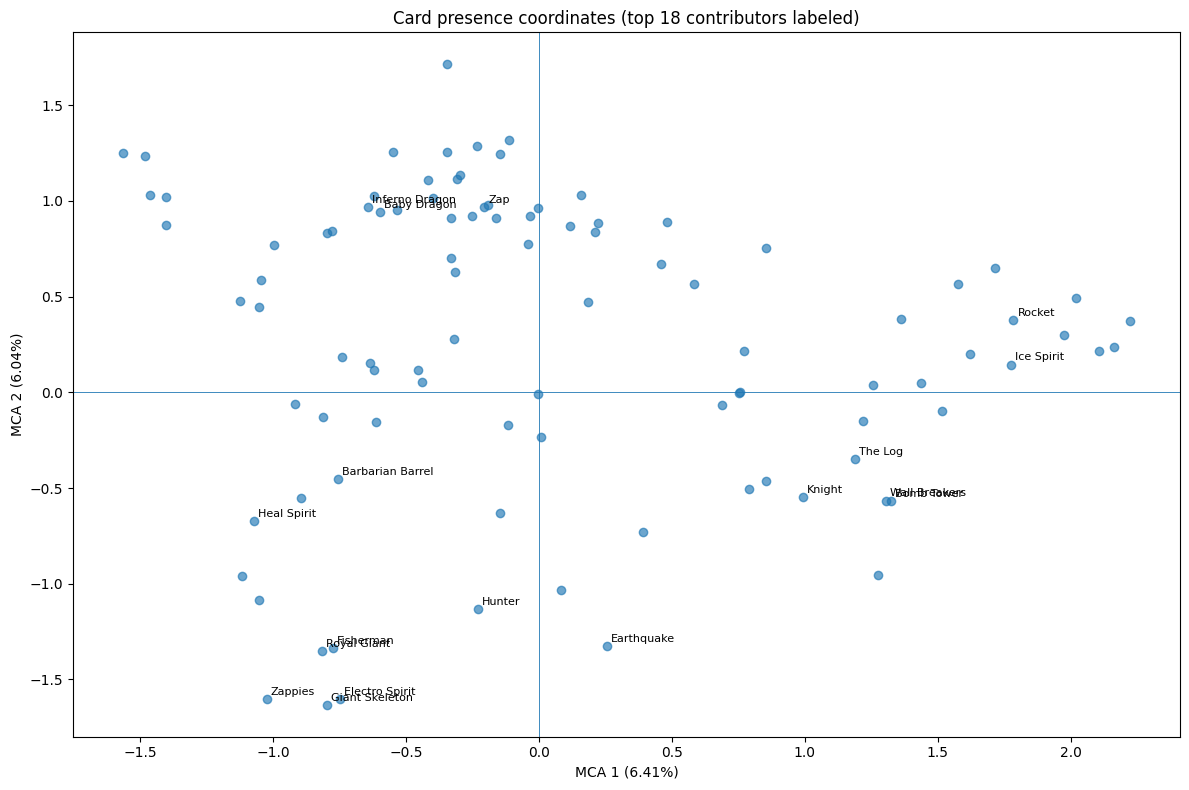

In [7]:
dims = [f"MCA_{i+1}" for i in range(d)]
category_names = np.concatenate([names[active], names[active]])
status = ["present"]*m + ["absent"]*m
categories = pd.DataFrame(G, columns=dims)
categories.insert(0, "status", status); categories.insert(0, "card", category_names)
contrib = pd.DataFrame(contributions, columns=dims)
contrib.insert(0, "status", status); contrib.insert(0, "card", category_names)
for dim in dims[:3]:
    table = categories.iloc[:m][["card", dim]].copy()
    table["contribution_percent"] = contrib.iloc[:m][dim].to_numpy()*100
    print(dim, "— highest contributing present categories")
    display(table.nlargest(10, "contribution_percent"))
if d >= 2:
    plt.figure(figsize=(12,8))
    plt.scatter(G[:m,0], G[:m,1], alpha=.65)
    top = np.argsort(contributions[:m,:2].sum(axis=1))[-18:]
    for j in top:
        plt.annotate(names[active][j], (G[j,0], G[j,1]), fontsize=8, xytext=(3,3), textcoords="offset points")
    plt.axhline(0, linewidth=.6); plt.axvline(0, linewidth=.6)
    plt.xlabel(f"MCA 1 ({inertia[0]*100:.2f}%)"); plt.ylabel(f"MCA 2 ({inertia[1]*100:.2f}%)")
    plt.title("Card presence coordinates (top 18 contributors labeled)")
    plt.tight_layout(); plt.savefig(OUT/"card_map.png", dpi=160); plt.show()

## 6. Export results for GMM
`X_mca` is the continuous deck representation for your teammate. Match row and player tag are metadata, not GMM features. This analysis is descriptive; for held-out evaluation, fit MCA on training data only, and account for repeated players.

In [8]:
scores = pd.DataFrame(F, columns=dims)
scores.insert(0, "winner.tag", matches["winner.tag"])
scores.insert(0, "match_row", np.arange(n))
pd.DataFrame(X, columns=names).to_csv(OUT/"binary_decks.csv", index=False)
scores.to_csv(OUT/"deck_coordinates.csv", index=False)
categories.to_csv(OUT/"card_coordinates.csv", index=False)
contrib.to_csv(OUT/"card_contributions.csv", index=False)
spectrum.to_csv(OUT/"explained_inertia.csv", index=False)
X_mca = scores[dims].to_numpy()
print("GMM input shape:", X_mca.shape)
display(scores.head())

GMM input shape: (1000, 20)


,match_row,winner.tag,MCA_1,MCA_2,MCA_3,MCA_4,MCA_5,MCA_6,MCA_7,MCA_8,...,MCA_11,MCA_12,MCA_13,MCA_14,MCA_15,MCA_16,MCA_17,MCA_18,MCA_19,MCA_20
0,0,#290QP2C,0.330687,-0.118762,-0.090468,0.104380,-0.003697,0.113306,0.159638,0.172408,...,0.117845,-0.001710,-0.096951,0.061988,-0.010270,0.052915,-0.038613,-0.105807,-0.210684,-0.170251
1,1,#YP9VPGUUG,-0.081998,0.222535,-0.095910,-0.130921,0.032842,0.027134,0.174866,-0.318686,...,0.050282,0.075182,0.195338,0.151064,-0.202020,-0.134505,-0.091498,0.155967,-0.065509,-0.165100
2,2,#9RGQ8YC,0.284155,-0.086962,-0.205411,0.093993,-0.101845,0.104356,-0.047296,0.032947,...,0.069934,-0.044862,0.113986,-0.018205,0.022415,0.056194,-0.009529,-0.074977,-0.007017,0.103354
3,3,#20QLJ2CLP,-0.314160,0.095013,0.002769,-0.184620,0.286997,0.198600,0.015049,0.015140,...,0.441095,0.280820,-0.033979,-0.159118,0.067301,0.049558,0.022267,-0.019012,0.007385,0.096547
4,4,#GYUQQCLV,-0.124039,0.390956,0.142488,-0.181268,-0.202821,0.103925,0.084040,-0.026470,...,-0.175717,0.094838,0.058653,0.271132,0.349721,0.079362,-0.121978,0.097739,-0.101119,0.025509


## 7. Download all results
Run this cell in Colab to download the generated CSVs and plots in one ZIP file.

In [9]:
import shutil
archive = shutil.make_archive("mca_results", "zip", OUT)
print(archive)
try:
    from google.colab import files
except ImportError:
    pass
else:
    files.download(archive)

/content/mca_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>